# Day 9 - Exploratory Data Analysis (EDA) on Student Performance

## Introduction

Exploratory Data Analysis (EDA) involves examining a dataset to understand its characteristics, distributions, trends, and relationships before applying machine learning algorithms.

This notebook uses the cleaned student performance dataset prepared on Day 8. Pandas is used for statistical analysis, while Matplotlib and Seaborn are used for data visualization.

## Learning Objectives

* Perform descriptive statistical analysis.
* Identify trends and patterns in student performance.
* Explore relationships between variables.
* Create five meaningful visualizations.
* Derive five evidence-based business insights.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("cleaned_student_performance.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())

Dataset shape: (30, 10)
Missing values: 0
Duplicate rows: 0


,student_id,name,department,study_year,age,attendance,python_marks,machine_learning_marks,projects_completed,join_date
0,S001,Aarav,AIML,2,20,60,45,57,2,2023-07-01
1,S002,Vivaan,IT,3,22,91,75,83,0,2023-07-04
2,S003,Aditya,CSE,3,22,77,53,60,0,2023-07-07
3,S004,Vihaan,ECE,3,21,77,72,68,4,2023-07-10
4,S005,Arjun,MECH,3,21,94,93,99,5,2023-07-13


## 1. Descriptive Statistics

Descriptive statistics summarize the central tendency, spread, and range of numerical data. The mean represents the average, the median represents the middle value, and the standard deviation indicates variation around the mean.

The `describe()` method provides count, mean, standard deviation, quartiles, minimum, and maximum values. Department-wise grouping is also used to compare academic performance and project completion.

In [2]:
numerical_columns = [
    "attendance",
    "python_marks",
    "machine_learning_marks",
    "projects_completed"
]

print("Descriptive statistics:")
display(df[numerical_columns].describe().round(2))

print("Department-wise averages:")
department_means = df.groupby("department")[
    ["python_marks", "machine_learning_marks", "projects_completed"]
].mean().round(2)

display(department_means)

print("Correlation matrix:")
correlation_matrix = df[numerical_columns].corr()
display(correlation_matrix.round(3))

Descriptive statistics:


,attendance,python_marks,machine_learning_marks,projects_completed
count,30.00,30.00,30.00,30.00
mean,77.97,70.63,70.77,3.63
std,11.48,14.70,19.92,2.41
min,57.00,41.00,35.00,0.00
25%,72.00,61.50,56.25,2.00
50%,77.00,72.00,74.00,4.00
75%,88.75,81.50,85.25,5.75
max,98.00,95.00,100.00,7.00


Department-wise averages:


,python_marks,machine_learning_marks,projects_completed
department,,,
AIML,70.80,82.30,3.70
CSE,64.12,61.88,3.50
ECE,75.00,60.25,3.75
IT,75.00,71.00,1.00
MECH,74.60,70.20,5.20


Correlation matrix:


,attendance,python_marks,machine_learning_marks,projects_completed
attendance,1.000,0.156,0.257,-0.066
python_marks,0.156,1.000,0.041,-0.137
machine_learning_marks,0.257,0.041,1.000,-0.090
projects_completed,-0.066,-0.137,-0.090,1.000



## 2. Identifying Trends and Patterns

Descriptive statistics summarise the dataset, while trend and pattern analysis helps identify differences between departments and relationships among student attributes.

This analysis examines:
- Average attendance and marks across departments.
- Differences in Python and Machine Learning performance.
- Patterns in the number of completed projects.
- Departments that show relatively higher or lower average results.

These observations help identify areas worth exploring through visualizations and support data-driven business insights. The results describe patterns in this dataset and do not establish cause-and-effect relationships.

In [10]:

# Identify trends and patterns in the dataset

department_summary = (
    df.groupby("department")[
        [
            "attendance",
            "python_marks",
            "machine_learning_marks",
            "projects_completed"
        ]
    ]
    .mean()
    .round(2)
)

print("Department-wise Average Performance and Activity:")
display(department_summary)

# Compare average marks across departments
print("Department with the highest average Python marks:")
print(department_summary["python_marks"].idxmax())

print("\nDepartment with the highest average Machine Learning marks:")
print(department_summary["machine_learning_marks"].idxmax())

# Compare attendance and project completion across departments
print("\nDepartment with the highest average attendance:")
print(department_summary["attendance"].idxmax())

print("\nDepartment with the highest average projects completed:")
print(department_summary["projects_completed"].idxmax())

# Compare subject-wise average marks
print("\nOverall Average Marks:")
print(df[["python_marks", "machine_learning_marks"]].mean().round(2))

Department-wise Average Performance and Activity:


,attendance,python_marks,machine_learning_marks,projects_completed
department,,,,
AIML,78.40,70.80,82.30,3.70
CSE,74.75,64.12,61.88,3.50
ECE,67.50,75.00,60.25,3.75
IT,85.33,75.00,71.00,1.00
MECH,86.20,74.60,70.20,5.20


Department with the highest average Python marks:
ECE

Department with the highest average Machine Learning marks:
AIML

Department with the highest average attendance:
MECH

Department with the highest average projects completed:
MECH

Overall Average Marks:
python_marks              70.63
machine_learning_marks    70.77
dtype: float64


## 3. Data Visualizations

Visualizations help reveal distributions, differences between groups, and possible relationships that may not be obvious from summary statistics alone.

The following charts use Matplotlib and Seaborn:

1. **Histogram:** Shows the distribution of student attendance.
2. **Grouped bar chart:** Compares average Python and ML marks by department.
3. **Scatter plot:** Examines the relationship between attendance and ML marks.
4. **Box plot:** Compares the distribution of Python marks across departments.
5. **Count plot:** Shows how many students completed different numbers of projects.

Each visualization includes a title and labeled axes to make its purpose clear.

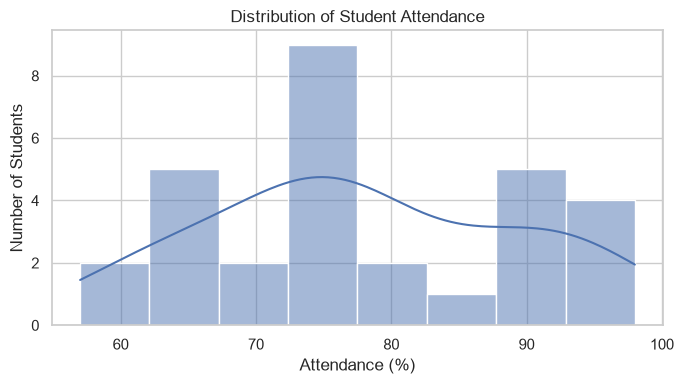

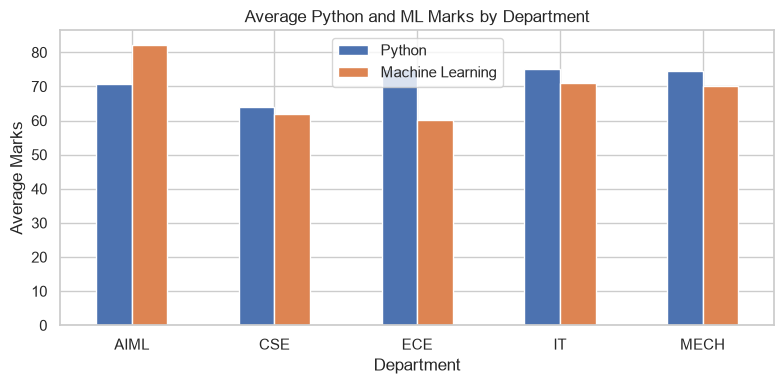

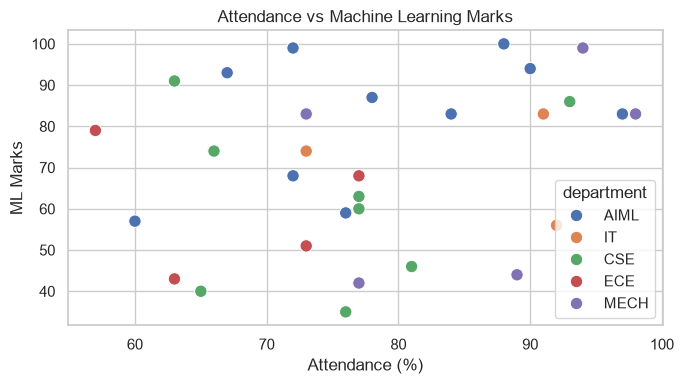

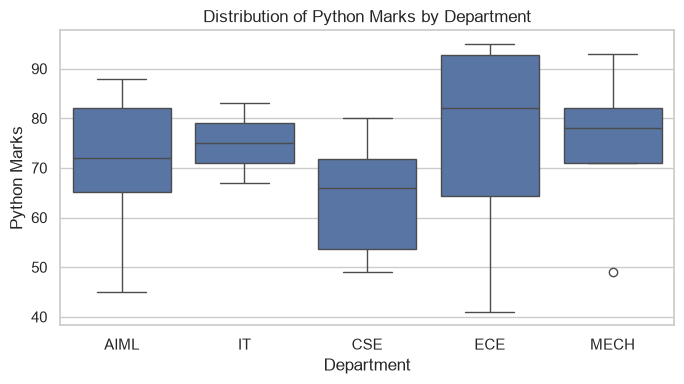

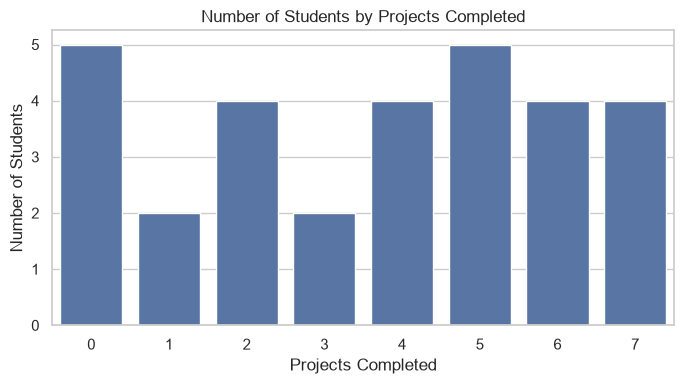

In [3]:
# 1. Distribution of attendance
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="attendance", bins=8, kde=True)
plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


# 2. Average Python and ML marks by department
department_marks = df.groupby("department")[
    ["python_marks", "machine_learning_marks"]
].mean()

department_marks.plot(kind="bar", figsize=(8, 4))
plt.title("Average Python and ML Marks by Department")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.legend(["Python", "Machine Learning"])
plt.tight_layout()
plt.show()


# 3. Attendance vs ML marks
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df,
    x="attendance",
    y="machine_learning_marks",
    hue="department",
    s=80
)
plt.title("Attendance vs Machine Learning Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("ML Marks")
plt.tight_layout()
plt.show()


# 4. Python marks by department
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="department", y="python_marks")
plt.title("Distribution of Python Marks by Department")
plt.xlabel("Department")
plt.ylabel("Python Marks")
plt.tight_layout()
plt.show()


# 5. Project completion distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="projects_completed")
plt.title("Number of Students by Projects Completed")
plt.xlabel("Projects Completed")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

## 4. Understanding Correlation

Correlation measures the direction and strength of a linear relationship between two numerical variables. Values range from -1 to +1.

* Positive correlation indicates that two variables tend to increase together.
* Negative correlation indicates that one tends to decrease as the other increases.
* Correlation near zero indicates little linear association.

Correlation does not establish causation. The following calculations help evaluate two relationships relevant to student performance.

In [8]:

# Analyse 6 meaningful relationships between numerical variables

selected_correlations = [
    ("attendance", "machine_learning_marks"),
    ("attendance", "python_marks"),
    ("python_marks", "machine_learning_marks"),
    ("projects_completed", "machine_learning_marks"),
    ("projects_completed", "python_marks"),
    ("age", "machine_learning_marks")
]

correlation_results = []

for var1, var2 in selected_correlations:
    value = df[var1].corr(df[var2])
    correlation_results.append({
        "Variable 1": var1,
        "Variable 2": var2,
        "Correlation": round(value, 3)
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df)

print("Interpretation guide:")
print("+1: Strong positive relationship")
print(" 0: Little or no linear relationship")
print("-1: Strong negative relationship")

,Variable 1,Variable 2,Correlation
0,attendance,machine_learning_marks,0.257
1,attendance,python_marks,0.156
2,python_marks,machine_learning_marks,0.041
3,projects_completed,machine_learning_marks,-0.090
4,projects_completed,python_marks,-0.137
5,age,machine_learning_marks,-0.146


Interpretation guide:
+1: Strong positive relationship
 0: Little or no linear relationship
-1: Strong negative relationship


## 4. Business Insights

The following insights summarize observed differences and relationships in the cleaned student dataset. Each finding includes numerical evidence and a practical implication. Because the dataset contains only 30 students, the findings should be treated as exploratory rather than generalized conclusions.

### Insight 1: Machine Learning Performance Varies Across Departments

AIML has the highest average machine learning marks at **82.30**, while ECE has the lowest at **60.25**. This difference may justify examining subject-specific learning needs and assessment patterns. However, AIML contains 10 students and ECE only 4, so the group sizes must be considered.

### Insight 2: Python and Machine Learning Marks Are Almost Uncorrelated

The Pearson correlation between Python marks and machine learning marks is approximately **0.041**, indicating almost no linear association in this sample. Strong Python performance alone is not a reliable indicator of ML marks in these records. Additional factors may need to be examined before making decisions about student support.

### Insight 3: Attendance Has Only a Weak Positive Relationship with ML Marks

The correlation between attendance and machine learning marks is approximately **0.257**. This suggests a weak positive linear relationship, not a strong connection. Attendance should therefore not be used alone to predict academic performance or identify students who need assistance.

### Insight 4: Project Completion Differs Between Departments

MECH students average **5.20 completed projects**, the highest department average, while IT students average **1.00**, the lowest. This difference may warrant further investigation into project opportunities, participation, or reporting practices. MECH has 5 students and IT has only 3, so this comparison is preliminary.

### Insight 5: Attendance Levels Also Differ Across Departments

MECH has the highest average attendance at **86.20%**, whereas ECE has the lowest at **67.50%**. ECE also has the lowest average ML marks, at **60.25**. These two observations occur in the same department, but they do not establish that lower attendance caused lower marks. A larger dataset would be needed to investigate the relationship more reliably.


In [9]:
print("VERIFICATION OF BUSINESS INSIGHTS")
print("=" * 45)

# 1. Highest and lowest ML averages
ml_means = df.groupby("department")["machine_learning_marks"].mean()

print("\n1. ML performance by department:")
print("Highest:", ml_means.idxmax(), round(ml_means.max(), 2))
print("Lowest:", ml_means.idxmin(), round(ml_means.min(), 2))

# 2. Python vs ML correlation
python_ml_corr = df[
    ["python_marks", "machine_learning_marks"]
].corr().iloc[0, 1]

print("\n2. Python vs ML correlation:", round(python_ml_corr, 3))

# 3. Attendance vs ML correlation
attendance_ml_corr = df[
    ["attendance", "machine_learning_marks"]
].corr().iloc[0, 1]

print("3. Attendance vs ML correlation:",
      round(attendance_ml_corr, 3))

# 4. Project completion by department
project_means = df.groupby("department")["projects_completed"].mean()

print("\n4. Average projects by department:")
print("Highest:", project_means.idxmax(),
      round(project_means.max(), 2))
print("Lowest:", project_means.idxmin(),
      round(project_means.min(), 2))

# 5. Attendance by department
attendance_means = df.groupby("department")["attendance"].mean()

print("\n5. Average attendance by department:")
print("Highest:", attendance_means.idxmax(),
      round(attendance_means.max(), 2))
print("Lowest:", attendance_means.idxmin(),
      round(attendance_means.min(), 2))

print("\nDepartment sample sizes:")
display(df["department"].value_counts().rename("student_count"))

VERIFICATION OF BUSINESS INSIGHTS

1. ML performance by department:
Highest: AIML 82.3
Lowest: ECE 60.25

2. Python vs ML correlation: 0.041
3. Attendance vs ML correlation: 0.257

4. Average projects by department:
Highest: MECH 5.2
Lowest: IT 1.0

5. Average attendance by department:
Highest: MECH 86.2
Lowest: ECE 67.5

Department sample sizes:


department
AIML    10
CSE      8
MECH     5
ECE      4
IT       3
Name: student_count, dtype: int64


## 7. Conclusion

Exploratory Data Analysis (EDA) helps transform raw data into meaningful information by summarising distributions, comparing groups, identifying patterns, and examining relationships between variables. In this project, the cleaned student performance dataset was analysed to explore differences in attendance, Python marks, Machine Learning marks, and project completion across departments.

Descriptive statistics provided an overview of the dataset, while department-wise analysis helped identify differences in average student performance and activity. Visualizations made these comparisons easier to interpret, and correlation analysis examined the direction and strength of selected relationships between numerical variables. The five business insights summarise the most relevant findings supported by the analysis.

### Key Takeaways

- Department-wise comparisons can reveal differences in average academic performance, attendance, and project activity.
- Visualizations help communicate distributions, comparisons, and relationships more clearly than tables alone.
- Correlation coefficients describe linear relationships but do not establish causation.
- Findings based on group averages should be interpreted carefully because individual student results may vary.
- EDA provides a foundation for asking better questions and deciding which variables require further investigation before building a machine learning model.

Overall, this project demonstrates how Pandas and data visualization techniques can be used to inspect a dataset, identify meaningful patterns, and develop evidence-based insights. The conclusions are limited to the available dataset and should not automatically be generalized to all students or departments.